# LAB 10 — Extractive QA fine-tuning trên SQuAD v1.1
Pretrained **`distilbert-base-uncased`** + head **Linear(768, 2)** cho start/end (`qa_model.QAModel`); loss L = (CE_start + CE_end)/2; hậu xử lý chọn span i ≤ j, dài ≤ 30 token, trong context, điểm = start_logit + end_logit.
- **Split:** SQuAD v1.1 train 87,599 câu hỏi → tách theo **bài viết (title)** ~5% làm **validation** (không trùng đoạn văn với train); **test = SQuAD dev chính thức** 10,570 câu hỏi.
- Huấn luyện trên **Kaggle GPU**; kết quả lưu trong `cache/`, chạy lại ở local sẽ nạp cache.

In [1]:
import sys, os, time, csv, json, random, re, warnings
from collections import Counter, defaultdict
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from transformers import AutoTokenizer
from qa_model import (MODEL_NAME, QAModel, qa_loss, prepare_train_features, prepare_eval_features, postprocess, squad_metrics,
                      exact_match, f1_score, best_over_golds, normalize_answer, keyword_baseline)
warnings.filterwarnings("ignore")
SEED = 2026; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); HW = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print("device:", DEVICE, HW)
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
os.makedirs("cache", exist_ok=True)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

C:\Users\dinhb\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu CPU


In [2]:
from datasets import load_dataset
squad = load_dataset("rajpurkar/squad")
def to_df(d): return pd.DataFrame({"id": list(d["id"]), "title": list(d["title"]), "context": list(d["context"]), "question": list(d["question"]), "answers": list(d["answers"])})
full_train, test = to_df(squad["train"]), to_df(squad["validation"])
titles = sorted(full_train.title.unique()); rng = np.random.RandomState(SEED)
val_titles = set(rng.choice(titles, int(round(0.05 * len(titles))), replace=False))
val = full_train[full_train.title.isin(val_titles)].reset_index(drop=True); train = full_train[~full_train.title.isin(val_titles)].reset_index(drop=True)
print(f"train {len(train):,} câu hỏi ({train.title.nunique()} bài) | validation {len(val):,} ({val.title.nunique()} bài) | test (SQuAD dev) {len(test):,} ({test.title.nunique()} bài)")
golds = lambda df: {r.id: r.answers["text"] for r in df.itertuples()}

train 83,590 câu hỏi (420 bài) | validation 4,009 (22 bài) | test (SQuAD dev) 10,570 (48 bài)


## 15–16. Core implementation — tokenizer(question, context, truncation="only_second", stride, overflow, offsets) → alignment → start/end

In [3]:
q, c = test.question[0], test.context[0]
enc = tok(q, c, truncation="only_second", max_length=128, stride=32, return_overflowing_tokens=True, return_offsets_mapping=True)
print("keys:", list(enc.keys()))
print("số window:", len(enc["input_ids"]), "| overflow_to_sample_mapping:", enc["overflow_to_sample_mapping"], "| độ dài context:", len(tok(c)["input_ids"]), "token")
a = test.answers[0]; s_char = a["answer_start"][0]; e_char = s_char + len(a["text"][0]); print("question:", q, "| gold:", a["text"][0], f"| ký tự [{s_char}, {e_char})")
from qa_model import char_to_token_span
for k in range(len(enc["input_ids"])):
    st, en = char_to_token_span(enc["offset_mapping"][k], enc.sequence_ids(k), s_char, e_char)
    ctx = [j for j, s in enumerate(enc.sequence_ids(k)) if s == 1]
    span = c[enc["offset_mapping"][k][st][0]:enc["offset_mapping"][k][en][1]] if st else "(không có trong window → [CLS])"
    print(f"window {k}: context ký tự [{enc['offset_mapping'][k][ctx[0]][0]}, {enc['offset_mapping'][k][ctx[-1]][1]}) | start_token={st} end_token={en} → {span}")
print("token_type_ids có trong output của tokenizer nhưng DistilBERT không dùng → không truyền vào model")

keys: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'overflow_to_sample_mapping']
số window: 2 | overflow_to_sample_mapping: [0, 0] | độ dài context: 159 token
question: Which NFL team represented the AFC at Super Bowl 50? | gold: Denver Broncos | ký tự [177, 191)
window 0: context ký tự [0, 583) | start_token=46 end_token=47 → Denver Broncos
window 1: context ký tự [416, 775) | start_token=0 end_token=0 → (không có trong window → [CLS])
token_type_ids có trong output của tokenizer nhưng DistilBERT không dùng → không truyền vào model


In [4]:
EPOCHS, BATCH, LR = 2, 32, 3e-5
def batches(enc, idx, keys):
    L = max(len(enc["input_ids"][i]) for i in idx)
    ids = torch.full((len(idx), L), tok.pad_token_id); am = torch.zeros((len(idx), L), dtype=torch.long)
    for r, i in enumerate(idx): n = len(enc["input_ids"][i]); ids[r, :n] = torch.tensor(enc["input_ids"][i]); am[r, :n] = 1
    extra = [torch.tensor([enc[k][i] for i in idx]) for k in keys]
    return ids, am, extra
@torch.no_grad()
def logits_of(model, enc, bs=128):
    model.eval(); S, E = [], []
    order = np.argsort([len(x) for x in enc["input_ids"]])            # gom các window cùng độ dài để nhanh hơn
    out_s, out_e = [None] * len(order), [None] * len(order)
    for b in range(0, len(order), bs):
        idx = order[b:b + bs]; ids, am, _ = batches(enc, idx, [])
        with torch.autocast(device_type="cuda", enabled=DEVICE.type == "cuda"):
            s, e = model(ids.to(DEVICE), am.to(DEVICE))
        s, e = s.float().cpu().numpy(), e.float().cpu().numpy()
        for r, i in enumerate(idx): n = len(enc["input_ids"][i]); out_s[i] = s[r, :n]; out_e[i] = e[r, :n]
    return out_s, out_e
@torch.no_grad()
def val_loss(model, enc, bs=128):
    model.eval(); tot = n = 0
    for b in range(0, len(enc["input_ids"]), bs):
        idx = list(range(b, min(b + bs, len(enc["input_ids"])))); ids, am, (sp, ep) = batches(enc, idx, ["start_positions", "end_positions"])
        with torch.autocast(device_type="cuda", enabled=DEVICE.type == "cuda"):
            s, e = model(ids.to(DEVICE), am.to(DEVICE))
        tot += qa_loss(s, e, sp.to(DEVICE), ep.to(DEVICE)).item() * len(idx); n += len(idx)
    return tot / n
def predict_df(model, df, L, stride):
    feats = prepare_eval_features(tok, df.question, df.context, L, stride); s, e = logits_of(model, feats)
    pp_ = postprocess(list(df.context), feats, s, e)
    return {df.id[i]: pp_[i] for i in range(len(df))}, len(feats["input_ids"])
def train_run(name, L, stride):
    path = f"cache/{name}.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    torch.manual_seed(SEED); rng = np.random.RandomState(SEED)
    tr = prepare_train_features(tok, train.question, train.context, train.answers, L, stride)
    va = prepare_train_features(tok, val.question, val.context, val.answers, L, stride)
    model = QAModel(MODEL_NAME).to(DEVICE); opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    n = len(tr["input_ids"]); steps = EPOCHS * int(np.ceil(n / BATCH)); warm = int(0.1 * steps)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (steps - s) / (steps - warm)))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    hist = dict(step=[], train_loss=[], epoch=[], val_loss=[], val_em=[], val_f1=[], epoch_s=[]); best = (-1, None, 0); step = 0; run = []
    for ep in range(EPOCHS):
        model.train(); t0 = time.time(); order = rng.permutation(n)
        for b in range(0, n, BATCH):
            ids, am, (sp, epos) = batches(tr, order[b:b + BATCH], ["start_positions", "end_positions"])
            with torch.autocast(device_type="cuda", enabled=DEVICE.type == "cuda"):
                s, e = model(ids.to(DEVICE), am.to(DEVICE)); loss = qa_loss(s, e, sp.to(DEVICE), epos.to(DEVICE))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
            run.append(loss.item()); step += 1
            if step % 200 == 0: hist["step"].append(step); hist["train_loss"].append(float(np.mean(run[-200:])))
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0; vl = val_loss(model, va); vp, _ = predict_df(model, val, L, stride)
        m = squad_metrics({k: v["text"] for k, v in vp.items()}, golds(val))
        for k_, v_ in (("epoch", ep + 1), ("val_loss", vl), ("val_em", m["exact_match"]), ("val_f1", m["f1"]), ("epoch_s", dt)): hist[k_].append(v_)
        print(f"{name} ep{ep+1}: train loss {np.mean(run[-500:]):.4f} | val loss {vl:.4f} | val EM {m['exact_match']:.2f} F1 {m['f1']:.2f} | {dt:.0f}s")
        if m["f1"] > best[0]: best = (m["f1"], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[1]); t0 = time.time(); tp, n_test_windows = predict_df(model, test, L, stride); infer = time.time() - t0
    res = dict(name=name, L=L, stride=stride, hist=hist, best_epoch=best[2], train_time=sum(hist["epoch_s"]), infer_s=infer, hardware=HW,
               params=sum(p.numel() for p in model.parameters()), n_train_windows=n, n_test_windows=n_test_windows,
               peak_mem_mb=(torch.cuda.max_memory_allocated() / 1e6 if DEVICE.type == "cuda" else float("nan")),
               test_pred=tp, test_metrics=squad_metrics({k: v["text"] for k, v in tp.items()}, golds(test)))
    if name == "QA_L384": torch.save({k: v.half() for k, v in model.state_dict().items()}, "cache/QA_L384_weights_fp16.pt")
    torch.save(res, path); del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return res

In [5]:
CONFIGS = {"QA_L384": (384, 128), "QA_L256": (256, 85), "QA_L128": (128, 42)}     # stride ≈ max_length / 3 (cùng tỉ lệ overlap)
runs = {n: train_run(n, *cfg) for n, cfg in CONFIGS.items()}
print({n: (round(r["test_metrics"]["exact_match"], 2), round(r["test_metrics"]["f1"], 2), round(r["train_time"])) for n, r in runs.items()})

{'QA_L384': (75.83, 84.26, 1393), 'QA_L256': (75.74, 84.32, 1168), 'QA_L128': (75.88, 84.2, 1239)}


### Kiểm tra độ bền (Prediction 1, 3, 4) — chạy trên Kaggle với model QA_L384
Trên 2,000 câu hỏi test (seed 2026), so sánh cùng câu hỏi trước/sau khi sửa context:
- **irrelevant:** thêm cuối context một câu lấy ngẫu nhiên từ bài khác;
- **distractor:** thêm cuối context một câu "mồi" = đáp án **giả** (đáp án của câu hỏi khác cùng loại wh-word) + phần còn lại của câu hỏi (bỏ wh-word, bỏ "?"), ví dụ "What is the capital of France?" → "Berlin is the capital of France.";
- **shuffle:** xáo thứ tự các câu của context (chỉ với context mà đáp án nằm trọn trong một câu).
EM/F1 tính theo chuỗi đáp án nên không cần tính lại vị trí ký tự.

In [6]:
def robustness():
    path = "cache/robustness.json"
    if os.path.exists(path): return json.load(open(path))
    model = QAModel(MODEL_NAME); model.load_state_dict({k: v.float() for k, v in torch.load("cache/QA_L384_weights_fp16.pt", map_location="cpu").items()}); model.to(DEVICE)
    rng = np.random.RandomState(SEED); sub = test.sample(min(2000, len(test)), random_state=SEED).reset_index(drop=True)
    split_s = lambda t: [s for s in re.split(r"(?<=[.!?])\s+", t) if s]
    pool = [s for ctx in train.context.sample(min(3000, len(train)), random_state=SEED) for s in split_s(ctx) if 8 <= len(s.split()) <= 30]
    wh = lambda q: (re.match(r"\s*(what|which|who|whom|whose|when|where|why|how)\b", q.lower()) or [None])[0]
    by_wh = defaultdict(list)
    for r in sub.itertuples(): by_wh[wh(r.question)].append(r.answers["text"][0])
    out = {}; variants = {"original": sub.copy()}
    irr = sub.copy(); irr["context"] = [c + " " + pool[rng.randint(len(pool))] for c in sub.context]; variants["irrelevant"] = irr
    dis = sub.copy(); fakes = []
    for k, r in enumerate(sub.itertuples()):
        cands = [a for a in by_wh[wh(r.question)] if normalize_answer(a) not in {normalize_answer(g) for g in r.answers["text"]}]
        fake = cands[rng.randint(len(cands))] if cands else "Nothing"; fakes.append(fake)
        rest = re.sub(r"^\s*(what|which|who|whom|whose|when|where|why|how)(\s+(many|much|long|old|year|type|kind))?\s*", "", r.question, flags=re.I).rstrip(" ?")
        dis.at[k, "context"] = r.context + " " + f"{fake} {rest}."
    variants["distractor"] = dis
    shf_rows = []
    for r in sub.itertuples():
        ss = split_s(r.context)
        if len(ss) > 2 and any(r.answers["text"][0] in s for s in ss):
            ss2 = ss[:]; rng.shuffle(ss2); shf_rows.append((r.id, " ".join(ss2)))
    shf_ids = {i for i, _ in shf_rows}; shf = sub[sub.id.isin(shf_ids)].copy(); shf["context"] = [dict(shf_rows)[i] for i in shf.id]
    variants["shuffle"] = shf.reset_index(drop=True); variants["original_shuffle_subset"] = sub[sub.id.isin(shf_ids)].reset_index(drop=True)
    for name, df in variants.items():
        p, _ = predict_df(model, df, 384, 128); pt = {k: v["text"] for k, v in p.items()}; g = golds(df)
        bp = {r.id: keyword_baseline(r.question, r.context) for r in df.itertuples()}
        out[name] = dict(n=len(df), model=squad_metrics(pt, g), baseline=squad_metrics(bp, g))
        if name == "distractor":
            fk = dict(zip(sub.id, fakes))
            out[name]["model_picked_fake"] = float(np.mean([exact_match(pt[i], fk[i]) or normalize_answer(fk[i]) in normalize_answer(pt[i]) for i in pt]))
            out[name]["baseline_picked_fake"] = float(np.mean([exact_match(bp[i], fk[i]) or normalize_answer(fk[i]) in normalize_answer(bp[i]) for i in bp]))
            out[name]["examples"] = [dict(q=r.question, gold=r.answers["text"][0], fake=fk[r.id], pred=pt[r.id]) for r in df.head(40).itertuples()]
    json.dump(out, open(path, "w")); return out
ROB = robustness()
print({k: (v["n"], round(v["model"]["f1"], 2), round(v["baseline"]["f1"], 2)) for k, v in ROB.items()})

{'original': (2000, 84.01, 22.75), 'irrelevant': (2000, 84.2, 22.75), 'distractor': (2000, 32.5, 5.06), 'shuffle': (1824, 83.48, 22.92), 'original_shuffle_subset': (1824, 84.3, 23.14)}


## 14. Experiment 1 — Context length (max_length 128 / 256 / 384, stride ≈ max_length/3, các thành phần khác giữ nguyên)

In [7]:
g_test = golds(test); rows = []
for n, r in runs.items():
    rows.append({"Max length": r["L"], "Stride": r["stride"], "EM": round(r["test_metrics"]["exact_match"], 2), "F1": round(r["test_metrics"]["f1"], 2),
                 "Training time (s)": round(r["train_time"]), "Train windows": r["n_train_windows"], "Test windows": r["n_test_windows"],
                 "Peak GPU (MB)": round(r["peak_mem_mb"]) if r["peak_mem_mb"] == r["peak_mem_mb"] else None, "Best epoch": r["best_epoch"]})
    for k in ("EM", "F1", "Training time (s)", "Train windows"): log("exp1_context_length", n, k, rows[-1][k])
t1 = pd.DataFrame(rows).sort_values("Max length").set_index("Max length"); display(t1)
ctx_len = np.array([len(tok(c)["input_ids"]) for c in test.context.unique()])
print(f"độ dài context test (token): trung vị {np.median(ctx_len):.0f}, > 128: {(ctx_len > 128).mean():.1%}, > 256: {(ctx_len > 256).mean():.1%}, > 384: {(ctx_len > 384).mean():.1%}")

,Stride,EM,F1,Training time (s),Train windows,Test windows,Peak GPU (MB),Best epoch
Max length,,,,,,,,
128,42,75.88,84.20,1239,177848,23473,2055,2
256,85,75.74,84.32,1168,92314,11945,2921,2
384,128,75.83,84.26,1393,84483,10784,3806,2


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (619 > 512). Running this sequence through the model will result in indexing errors


độ dài context test (token): trung vị 148, > 128: 65.4%, > 256: 8.1%, > 384: 1.4%


**Nhận xét Experiment 1.**
- Ba cấu hình gần như **bằng nhau**: EM 75.74–75.88, F1 84.20–84.32. Chênh lệch dưới 0.15 điểm, nhỏ hơn dao động do seed, nên không kết luận cấu hình nào tốt hơn.
- Lý do: có **sliding window**, nên dù max_length nhỏ thì đáp án vẫn nằm trong ít nhất một window. Trong `tokenizer_alignment.ipynb`, độ phủ là khoảng 100% ở cả ba độ dài. Context SQuAD cũng ngắn (trung vị 148 token, chỉ 1.4% dài hơn 384).
- Cái giá nằm ở **chi phí**:
  - L = 128 sinh **2.1 lần** số window train (177,848 so với 84,483) và **2.2 lần** số window test. Suy luận chậm hơn khoảng 50% (39 s so với 26 s), nhưng VRAM chỉ cần 2.1 GB so với 3.8 GB.
  - L = 256 có thời gian train ngắn nhất (1,168 s) vì attention O(L²) rẻ hơn mà số window chỉ tăng 9%.
- Nếu không có sliding window (chỉ truncate), L = 128 sẽ mất 13.5% đáp án. Kết quả bằng nhau ở đây là nhờ stride, không phải vì context dài là vô ích.

## 17. Experiment 2 — Learning curves → `learning_curves.png`

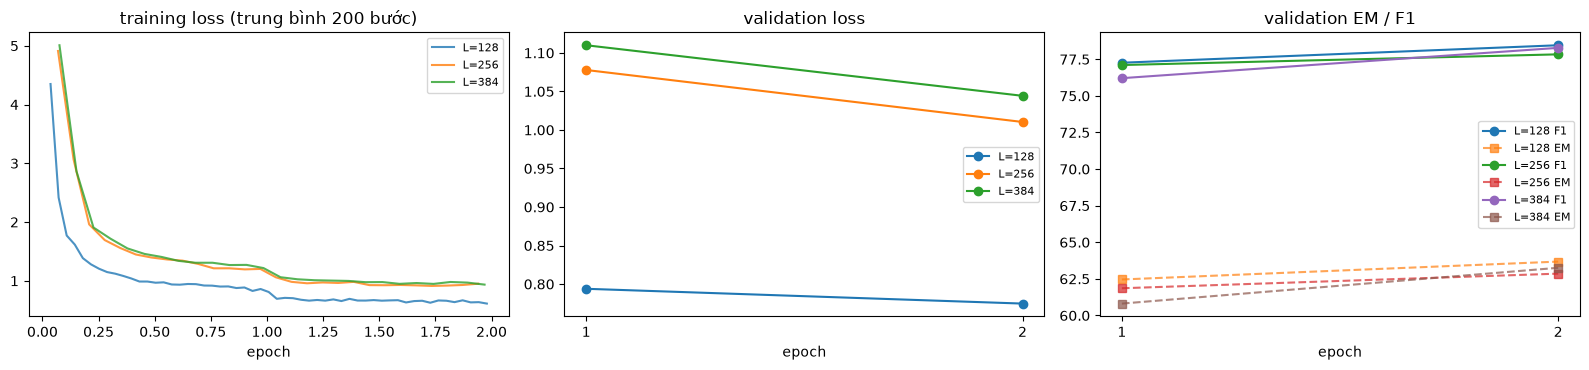

val_loss  val_EM  val_F1
run     epoch                          
QA_L384 1        1.1099   60.81   76.21
        2        1.0443   63.26   78.28
QA_L256 1        1.0778   61.86   77.11
        2        1.0104   62.86   77.84
QA_L128 1        0.7939   62.46   77.27
        2        0.7747   63.68   78.46

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for n, r in sorted(runs.items(), key=lambda t: t[1]["L"]):
    h = r["hist"]; steps_per_ep = int(np.ceil(r["n_train_windows"] / BATCH))
    axes[0].plot(np.array(h["step"]) / steps_per_ep, h["train_loss"], label=f"L={r['L']}", alpha=.8)
    axes[1].plot(h["epoch"], h["val_loss"], "o-", label=f"L={r['L']}"); axes[2].plot(h["epoch"], h["val_f1"], "o-", label=f"L={r['L']} F1")
    axes[2].plot(h["epoch"], h["val_em"], "s--", label=f"L={r['L']} EM", alpha=.7)
axes[0].set_title("training loss (trung bình 200 bước)"); axes[0].set_xlabel("epoch"); axes[1].set_title("validation loss"); axes[2].set_title("validation EM / F1")
for a in axes[1:]: a.set_xlabel("epoch"); a.set_xticks([1, 2])
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=130); plt.show()
display(pd.DataFrame([{"run": n, "epoch": e, "val_loss": round(vl, 4), "val_EM": round(em, 2), "val_F1": round(f1, 2)} for n, r in runs.items()
                      for e, vl, em, f1 in zip(r["hist"]["epoch"], r["hist"]["val_loss"], r["hist"]["val_em"], r["hist"]["val_f1"])]).set_index(["run", "epoch"]))

**Nhận xét learning curves.**
- Training loss giảm nhanh trong 0.25 epoch đầu: head start/end được khởi tạo ngẫu nhiên, còn backbone đã biết ngôn ngữ.
- Validation loss vẫn giảm ở epoch 2 với cả ba cấu hình, và validation F1 tăng thêm 0.7–2.1 điểm. Chưa có dấu hiệu overfit, nên best epoch = 2.
- Validation loss của L = 128 thấp hơn hẳn (0.77 so với 1.04) **nhưng không có nghĩa model tốt hơn**: L = 128 có nhiều window không chứa đáp án, nhãn (0, 0) = [CLS], rất dễ đoán đúng nên kéo loss trung bình xuống. Loss giữa các max_length khác nhau **không so sánh trực tiếp được**; phải so bằng EM/F1.
- Validation EM (khoảng 63) thấp hơn test EM (khoảng 76) vì validation lấy từ train nên mỗi câu có **1 gold**, còn SQuAD dev có **3 gold** và EM lấy max. Hai con số này không cùng thang đo.

## 20–21. Experiment 3 — EM vs F1: baseline (keyword overlap) vs fine-tuned Transformer → `em_f1_analysis.png`

,EM,F1
Model,,
Baseline (keyword overlap → câu → span),10.55,22.51
Fine-tuned DistilBERT (L=384),75.83,84.26


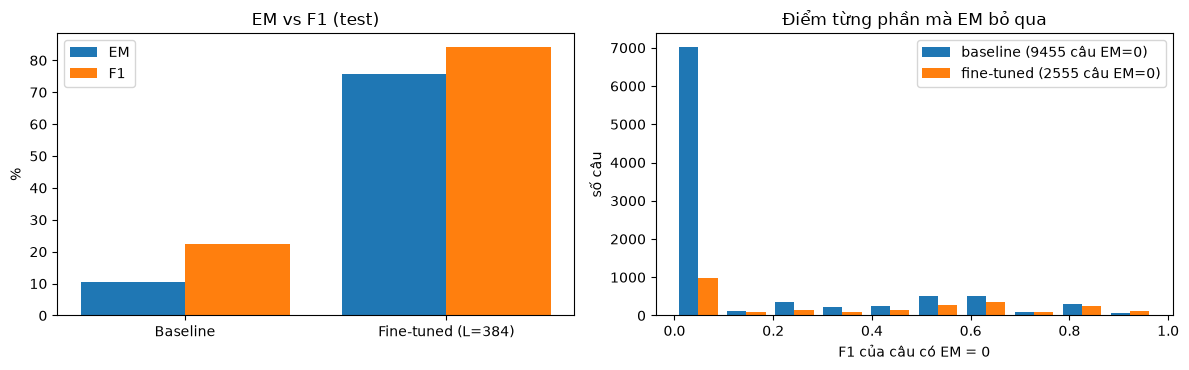

fine-tuned: 1584 câu EM = 0 nhưng F1 > 0 (15.0%), F1 trung bình 0.56

Q: What is a term for schools that receive government assistance?
  gold: ['aided', 'aided', 'aided'] | pred: "aided' schools" | F1 = 0.67

Q: What city did Super Bowl 50 take place in?
  gold: ['Santa Clara', 'Santa Clara', 'Santa Clara'] | pred: 'Santa Clara, California' | F1 = 0.80

Q: Low doses of anti-inflammatories are sometimes used with what classes of drugs?
  gold: ['cytotoxic or immunosuppressive drugs', 'cytotoxic or immunosuppressive', 'Cytotoxic drugs'] | pred: 'cytotoxic or immunosuppressive drugs such as methotrexate or azathioprine' | F1 = 0.62

Q: What plateau has groups of clay pits?
  gold: ['moraine', 'moraine', 'moraine'] | pred: 'plain moraine plateau' | F1 = 0.50

Q: What is a connection identifier 
  gold: ['a connection identifier rather than address information and are negotiated between endpoints so that they are delivered in order and with error checking', 'negotiated between endpoints'] 

In [9]:
best = runs["QA_L384"]; pred = {k: v["text"] for k, v in best["test_pred"].items()}
base = {r.id: keyword_baseline(r.question, r.context) for r in test.itertuples()}
mb = squad_metrics(base, g_test); mt = best["test_metrics"]
t3 = pd.DataFrame([{"Model": "Baseline (keyword overlap → câu → span)", "EM": round(mb["exact_match"], 2), "F1": round(mb["f1"], 2)},
                   {"Model": "Fine-tuned DistilBERT (L=384)", "EM": round(mt["exact_match"], 2), "F1": round(mt["f1"], 2)}]).set_index("Model"); display(t3)
for m_, r_ in (("baseline", mb), ("QA_L384", mt)):
    log("exp3_em_f1", m_, "EM", round(r_["exact_match"], 2)); log("exp3_em_f1", m_, "F1", round(r_["f1"], 2))
em_q = {i: best_over_golds(exact_match, pred[i], g_test[i]) for i in g_test}; f1_q = {i: best_over_golds(f1_score, pred[i], g_test[i]) for i in g_test}
emb = {i: best_over_golds(exact_match, base[i], g_test[i]) for i in g_test}; f1b = {i: best_over_golds(f1_score, base[i], g_test[i]) for i in g_test}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(2); ax[0].bar(x - .2, [mb["exact_match"], mt["exact_match"]], .4, label="EM"); ax[0].bar(x + .2, [mb["f1"], mt["f1"]], .4, label="F1")
ax[0].set_xticks(x); ax[0].set_xticklabels(["Baseline", "Fine-tuned (L=384)"]); ax[0].set_ylabel("%"); ax[0].legend(); ax[0].set_title("EM vs F1 (test)")
wrong = [f1_q[i] for i in g_test if em_q[i] == 0]; wrong_b = [f1b[i] for i in g_test if emb[i] == 0]
ax[1].hist([wrong_b, wrong], bins=10, label=[f"baseline ({len(wrong_b)} câu EM=0)", f"fine-tuned ({len(wrong)} câu EM=0)"]); ax[1].set_xlabel("F1 của câu có EM = 0"); ax[1].set_ylabel("số câu"); ax[1].legend(); ax[1].set_title("Điểm từng phần mà EM bỏ qua")
plt.tight_layout(); plt.savefig("em_f1_analysis.png", dpi=130); plt.show()
partial = [i for i in g_test if em_q[i] == 0 and f1_q[i] > 0]; print(f"fine-tuned: {len(partial)} câu EM = 0 nhưng F1 > 0 ({len(partial)/len(g_test):.1%}), F1 trung bình {np.mean([f1_q[i] for i in partial]):.2f}")
rng = np.random.RandomState(SEED); T_ = test.set_index("id")
for i in rng.choice(partial, 6, replace=False):
    print(f"\nQ: {T_.question[i]}\n  gold: {g_test[i]} | pred: {pred[i]!r} | F1 = {f1_q[i]:.2f}")

**Nhận xét Experiment 3.**
- Fine-tuned DistilBERT hơn baseline keyword overlap **+65 EM / +62 F1**. Baseline thường chọn đúng câu nhưng không biết **cắt span** ở đâu, nên F1 (22.5) cao gấp đôi EM (10.6).
- 1,584 câu (15%) có EM = 0 nhưng F1 > 0, F1 trung bình 0.56. Các ví dụ cho thấy phần lớn là **lệch ranh giới vài từ** so với gold: "Santa Clara, California" vs "Santa Clara", "24 of the 32" vs "24". Về nội dung, nhiều câu trong số này có thể coi là đúng. EM phạt nặng các lỗi này, F1 thì cho điểm một phần.
- Khoảng cách F1 − EM của model là 8.4 điểm: một phần không nhỏ của "lỗi" là lỗi ranh giới chứ không phải hiểu sai câu hỏi.

## 22. Experiment 4 — Question/context matching (lexical overlap)
overlap = tỉ lệ từ khóa (bỏ stopword) của câu hỏi xuất hiện trong **câu chứa đáp án gold**. Chia test thành 4 nhóm theo overlap.

In [10]:
from qa_model import STOP, WORD_RE
def answer_sentence(ctx, start):
    for m in re.finditer(r"[^.!?]+[.!?]*", ctx):
        if m.start() <= start < m.end(): return ctx[m.start():m.end()]
    return ctx
ov = {}
for r in test.itertuples():
    qk = {w.lower() for w in WORD_RE.findall(r.question)} - STOP; sent = {w.lower() for w in WORD_RE.findall(answer_sentence(r.context, r.answers["answer_start"][0]))}
    ov[r.id] = len(qk & sent) / max(1, len(qk))
bins = [(-0.01, 0.25, "≤ 25%"), (0.25, 0.5, "25–50%"), (0.5, 0.75, "50–75%"), (0.75, 1.01, "> 75%")]; rows = []
for lo, hi, lab in bins:
    ids = [i for i in g_test if lo < ov[i] <= hi]
    rows.append({"Overlap question ↔ câu đáp án": lab, "n": len(ids), "Model EM": round(100 * np.mean([em_q[i] for i in ids]), 2), "Model F1": round(100 * np.mean([f1_q[i] for i in ids]), 2),
                 "Baseline EM": round(100 * np.mean([emb[i] for i in ids]), 2), "Baseline F1": round(100 * np.mean([f1b[i] for i in ids]), 2)})
    log("exp4_overlap", lab, "model_f1|baseline_f1|n", f"{rows[-1]['Model F1']}|{rows[-1]['Baseline F1']}|{len(ids)}")
t4 = pd.DataFrame(rows).set_index("Overlap question ↔ câu đáp án"); display(t4)

,n,Model EM,Model F1,Baseline EM,Baseline F1
Overlap question ↔ câu đáp án,,,,,
≤ 25%,1850,64.65,73.44,2.49,8.65
25–50%,3253,73.72,82.95,7.41,19.05
50–75%,3106,79.78,87.60,12.59,25.56
> 75%,2361,82.30,90.13,18.51,34.15


**Nhận xét Experiment 4.**
- Cả hai phương pháp đều tốt dần khi overlap giữa câu hỏi và câu đáp án tăng:
  - Model: F1 73.4 → 90.1 (+16.7).
  - Baseline: F1 8.7 → 34.2, gấp 4 lần.
- Baseline gần như **chỉ dựa vào** trùng từ. Model cũng dựa vào trùng từ, nhưng vẫn đạt F1 73 khi overlap ≤ 25%: nó có xử lý được paraphrase và từ đồng nghĩa (nhờ pretraining), chỉ là kém hơn.

In [11]:
display(pd.DataFrame({k: {"n": v["n"], "Model EM": round(v["model"]["exact_match"], 2), "Model F1": round(v["model"]["f1"], 2),
                          "Baseline EM": round(v["baseline"]["exact_match"], 2), "Baseline F1": round(v["baseline"]["f1"], 2)} for k, v in ROB.items() if k != "examples"}).T.rename_axis("context"))
print(f"distractor: model chọn đúng đáp án giả {ROB['distractor']['model_picked_fake']:.1%} | baseline {ROB['distractor']['baseline_picked_fake']:.1%}")
for k in ("irrelevant", "distractor", "shuffle"):
    ref = ROB["original_shuffle_subset" if k == "shuffle" else "original"]["model"]
    log("robustness", k, "model_f1|delta_vs_original", f"{ROB[k]['model']['f1']:.2f}|{ROB[k]['model']['f1'] - ref['f1']:+.2f}")
for e in [x for x in ROB["distractor"]["examples"] if normalize_answer(x["fake"]) in normalize_answer(x["pred"])][:4]:
    print(f"Q: {e['q']} | gold: {e['gold']} | câu mồi chứa: {e['fake']} | pred: {e['pred']}")

,n,Model EM,Model F1,Baseline EM,Baseline F1
context,,,,,
original,2000.0,75.65,84.01,11.00,22.75
irrelevant,2000.0,76.05,84.20,11.00,22.75
distractor,2000.0,28.65,32.50,2.50,5.06
shuffle,1824.0,74.89,83.48,11.18,22.92
original_shuffle_subset,1824.0,75.93,84.30,11.35,23.14


distractor: model chọn đúng đáp án giả 58.0% | baseline 69.4%
Q: What was Tugh's Chinese-style name? | gold: Emperor Wenzong | câu mồi chứa: Hmong or Laotian | pred: Hmong or Laotian
Q: What was the occasion when he claimed he'd made the death ray? | gold: at a luncheon in his honor | câu mồi chứa: 1st century BC | pred: 1st century BC
Q: How did france differ from Britain in managing its colonies? | gold: small numbers of settlers | câu mồi chứa: 39 | pred: 39
Q: Who did the BBC work with to reconstruct some of The Invasion episodes? | gold: Cosgrove Hall | câu mồi chứa: Vince Lombardi | pred: Vince Lombardi


**Nhận xét robustness (Prediction 1, 3, 4).**
- **irrelevant**: F1 84.01 → 84.20 (+0.2), coi như không ảnh hưởng. Model bỏ qua được câu lạc đề.
- **distractor**: F1 84.0 → **32.5 (−51.5)**, EM 75.7 → 28.7.
  - Model chọn đúng **đáp án giả** trong 58% câu hỏi, dù đáp án giả thường **sai loại** (câu "Who conceptualized the aeolipile?" được trả lời "New England Patriots"; "What type/genre of TV show is Doctor Who?" được trả lời "8–4–4 system").
  - Model dựa rất nhiều vào "câu nào lặp lại câu hỏi nhất", giống kết quả adversarial SQuAD của Jia & Liang (2017).
  - Câu mồi ở đây mạnh hơn bản gốc vì chép gần nguyên văn câu hỏi.
- **shuffle**: F1 84.30 → 83.48 (−0.8) trên cùng tập 1,824 câu. Ảnh hưởng nhỏ: câu chứa đáp án vẫn nguyên, chỉ mất liên kết giữa các câu (đại từ, thứ tự sự kiện).

## 23. Experiment 5 — Answer length (số word của gold answer đầu tiên) → `answer_length_analysis.png`

,n,EM,F1,Baseline EM,Baseline F1
Answer length,,,,,
1,3429,79.76,84.83,16.10,25.60
2–3,4575,78.67,85.75,9.79,22.43
4–6,1648,71.84,83.81,5.83,19.79
7+,918,54.14,75.47,2.07,16.29


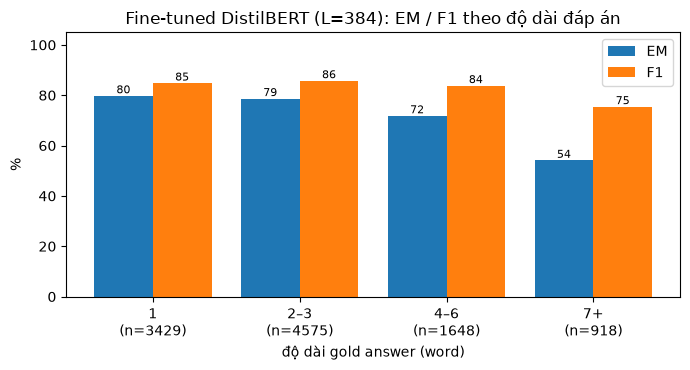

In [12]:
alen = {r.id: len(r.answers["text"][0].split()) for r in test.itertuples()}
groups = [("1", 1, 1), ("2–3", 2, 3), ("4–6", 4, 6), ("7+", 7, 999)]; rows = []
for lab, lo, hi in groups:
    ids = [i for i in g_test if lo <= alen[i] <= hi]
    rows.append({"Answer length": lab, "n": len(ids), "EM": round(100 * np.mean([em_q[i] for i in ids]), 2), "F1": round(100 * np.mean([f1_q[i] for i in ids]), 2),
                 "Baseline EM": round(100 * np.mean([emb[i] for i in ids]), 2), "Baseline F1": round(100 * np.mean([f1b[i] for i in ids]), 2)})
    log("exp5_answer_length", lab, "EM|F1|n", f"{rows[-1]['EM']}|{rows[-1]['F1']}|{len(ids)}")
t5 = pd.DataFrame(rows).set_index("Answer length"); display(t5)
fig, ax = plt.subplots(figsize=(7, 3.8)); x = np.arange(4)
ax.bar(x - .2, t5.EM, .4, label="EM"); ax.bar(x + .2, t5.F1, .4, label="F1")
for xi, (e_, f_) in enumerate(zip(t5.EM, t5.F1)): ax.text(xi - .2, e_ + 1, f"{e_:.0f}", ha="center", fontsize=8); ax.text(xi + .2, f_ + 1, f"{f_:.0f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(t5.index, t5.n)]); ax.set_xlabel("độ dài gold answer (word)"); ax.set_ylabel("%"); ax.set_ylim(0, 105)
ax.set_title("Fine-tuned DistilBERT (L=384): EM / F1 theo độ dài đáp án"); ax.legend(); plt.tight_layout(); plt.savefig("answer_length_analysis.png", dpi=130); plt.show()

**Nhận xét Experiment 5.**
- EM giảm rõ theo độ dài đáp án: 79.8 (1 word) → 78.7 (2–3) → 71.8 (4–6) → **54.1** (7+), tức giảm 25.6 điểm.
- F1 giảm ít hơn nhiều (84.8 → 75.5, −9.4): với span dài, lệch một đầu vẫn còn trùng nhiều từ.
- Span 7+ word thường là mệnh đề hoặc lý do ("because…", "many elderly people…"). Ranh giới của chúng mơ hồ, nên 3 người gán nhãn SQuAD cũng hay chọn khác nhau.
- F1 của nhóm 2–3 word (85.8) nhỉnh hơn nhóm 1 word (84.8): với đáp án 1 word, sai là F1 = 0, không có điểm một phần.

## 24–25. Error analysis — wrong start vs wrong end
So với gold có F1 cao nhất, sau khi bỏ khoảng trắng/dấu câu ở hai đầu: **wrong end** = start đúng, end sai; **wrong start** = end đúng, start sai; **wrong span** = sai cả hai (chồng lấp gold = *wrong boundary/partial*; không chồng lấp = *chọn sai chỗ*).

In [13]:
def trim(ctx, s, e):
    while s < e and not ctx[s].isalnum(): s += 1
    while e > s and not ctx[e - 1].isalnum(): e -= 1
    return s, e
cats = defaultdict(list); bigger = Counter()
for r in test.itertuples():
    p = best["test_pred"][r.id]
    if em_q[r.id] == 1: continue
    gs = [(a, s) for a, s in zip(r.answers["text"], r.answers["answer_start"])]
    ga, gs_ = max(gs, key=lambda t: f1_score(p["text"], t[0])); g0, g1 = trim(r.context, gs_, gs_ + len(ga)); p0, p1 = trim(r.context, p["char_start"], p["char_end"])
    so, eo = p0 == g0, p1 == g1
    if so and eo: cats["same span (khác chuẩn hóa)"].append(r.id); continue
    k = "wrong end" if so else "wrong start" if eo else ("wrong span (chồng lấp)" if p0 < g1 and g0 < p1 else "wrong span (sai chỗ)")
    cats[k].append((r.id, ga, p["text"])); bigger[(k, "dài hơn gold" if (p1 - p0) > (g1 - g0) else "ngắn hơn gold")] += 1
tot = sum(len(v) for v in cats.values())
display(pd.DataFrame([{"Loại lỗi": k, "n": len(v), "% lỗi": round(100 * len(v) / tot, 1)} for k, v in cats.items()]).set_index("Loại lỗi"))
display(pd.Series(bigger).rename("n").to_frame())
for k, v in cats.items(): log("error_start_end", k, "n", len(v))
rng = np.random.RandomState(SEED)
for k in ("wrong start", "wrong end", "wrong span (chồng lấp)", "wrong span (sai chỗ)"):
    print(f"\n===== {k} =====")
    for j in rng.choice(len(cats[k]), min(5, len(cats[k])), replace=False):
        i, ga, pt = cats[k][j]; print(f"Q: {T_.question[i]}\n   gold: {ga!r} | pred: {pt!r} | context: ...{answer_sentence(T_.context[i], T_.answers[i]['answer_start'][0]).strip()[:160]}")

,n,% lỗi
Loại lỗi,,
wrong end,549,21.5
wrong span (sai chỗ),1177,46.1
wrong start,654,25.6
wrong span (chồng lấp),174,6.8
same span (khác chuẩn hóa),1,0.0


n
wrong end              dài hơn gold   343
                       ngắn hơn gold  206
wrong span (sai chỗ)   dài hơn gold   529
                       ngắn hơn gold  648
wrong start            dài hơn gold   400
wrong span (chồng lấp) dài hơn gold   108
wrong start            ngắn hơn gold  254
wrong span (chồng lấp) ngắn hơn gold   66


===== wrong start =====
Q: How much did the population of Victoria increase in ten years after the discovery of gold?
   gold: '76,000 to 540,000' | pred: 'sevenfold from 76,000 to 540,000' | context: ...In ten years the population of Victoria increased sevenfold from 76,000 to 540,000.
Q: Where did Tesla and Twain hang out?
   gold: 'in his lab' | pred: 'his lab' | context: ...In middle age, Tesla became a close friend of Mark Twain; they spent a lot of time together in his lab and elsewhere.
Q: What is usual form of oxygen bound compounds?
   gold: 'oxides' | pred: 'chemical bonds with almost all other elements to give corresponding oxides' | context: ...Due to its electronegativity, oxygen forms chemical bonds with almost all other elements to give corresponding oxides.
Q: What did Luther think was required to stop the violence?
   gold: "trust God's word" | pred: "God's word" | context: ...He wrote to the Elector: "During my absence, Satan has entered my sheepfold, and committed r

**Nhận xét error analysis.**
- 2,555 câu sai (EM = 0) chia theo ranh giới:
  - Wrong span sai chỗ: **46%**. Chọn cụm khác hẳn, thường là thực thể **cùng loại** ở gần (Los Angeles area / San Diego area, 1809 / 1807, Russell T Davies / Christopher Eccleston).
  - Wrong start: 26% (654).
  - Wrong end: 21% (549).
  - Wrong span chồng lấp: 7%.
- Lỗi ranh giới (start, end, chồng lấp) chiếm **54%** số câu sai, nhưng đa số vẫn được F1 cao.
- **#wrong start (654) > #wrong end (549)**. Trong cả hai loại, dự đoán **dài hơn gold** nhiều hơn ngắn hơn (start 400/254, end 343/206): model hay kéo thêm từ vào span, như "sevenfold from 76,000 to 540,000", "13 per cent", "Rhone and Danube".
- Phân tích chi tiết và giả thuyết nguyên nhân: xem `error_analysis.md`.

## 27. Application — Document QA (`document_qa.py`)
Mini QA system: câu hỏi + một tài liệu tự viết (FAQ về các lab của môn học, viết bằng tiếng Anh vì model fine-tune trên SQuAD tiếng Anh) → model → answer span. Đánh giá trên 15 câu hỏi có gold.

In [14]:
from document_qa import DocumentQA, COURSE_FAQ, FAQ_EVAL
dqa = DocumentQA("cache/QA_L384_weights_fp16.pt", device="cpu")
res_doc = dqa.evaluate(COURSE_FAQ, FAQ_EVAL)
print(f"Document QA (15 câu): EM {res_doc['exact_match']:.1f} | F1 {res_doc['f1']:.1f} | tài liệu {res_doc['doc_tokens']} token → {res_doc['n_windows']} window")
display(pd.DataFrame(res_doc["rows"]))
log("document_qa", "course_faq_15q", "EM|F1", f"{res_doc['exact_match']:.1f}|{res_doc['f1']:.1f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3354.80it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Document QA (15 câu): EM 73.3 | F1 88.4 | tài liệu 425 token → 2 window


,question,gold,prediction,EM,F1,window
0,Who is the lecturer of the course?,Pham Ngoc Hai,Pham Ngoc Hai,1.0,1.000,0
1,At which university is the course taught?,VNU University of Science,VNU University of Science,1.0,1.000,0
2,Which dataset does LAB 05 use?,IMDb movie review dataset,IMDb movie review,0.0,0.857,0
3,When was the deadline of LAB 06?,23:59 on 28 October 2026,25 November 2026,0.0,0.333,1
4,What kind of positional encoding is used in LA...,sinusoidal positional encoding,multi-head attention and sinusoidal,0.0,0.400,0
5,When was LAB 07 due?,4 November 2026,4 November 2026,1.0,1.000,0
6,What does LAB 08 compare full fine-tuning with?,freezing the encoder,freezing the encoder,1.0,1.000,0
7,Which dataset is used for named entity recogni...,CoNLL-2003 dataset,CoNLL-2003,1.0,1.000,0
8,What are the entity types of CoNLL-2003?,"person, organization, location and miscellaneous","person, organization, location and miscellaneous",1.0,1.000,0
9,What is SQuAD?,Stanford Question Answering Dataset,extractive question answering on the Stanford ...,0.0,0.667,0


**Nhận xét Document QA.**
- Tài liệu 425 token, chia thành 2 window (L = 384, stride = 128). Câu hỏi về nửa sau tài liệu (LAB 10–12) được trả lời ở **window 1**, nên sliding window hoạt động đúng trên tài liệu ngoài SQuAD.
- Đạt EM 73.3 / F1 88.4 trên 15 câu, tương đương SQuAD.
- Lỗi đáng chú ý nhất: **"When was the deadline of LAB 06?" được trả lời "25 November 2026"** (deadline của LAB 10, ở window 1). Đây đúng là lỗi distractor ngoài thực tế: câu "The deadline for LAB 10 is …" trùng từ "deadline" với câu hỏi hơn câu đúng ("its deadline was …", dùng đại từ "its" thay cho LAB 06).
- Các lỗi khác là lỗi ranh giới:
  - "IMDb movie review" thiếu "dataset".
  - "extractive question answering on the Stanford…" thừa đầu.
  - "multi-head attention and sinusoidal" lấy cả danh sách.

## 30. Reproducibility

In [15]:
r = runs["QA_L384"]
display(pd.DataFrame({"": {"Model": f"{MODEL_NAME} + Linear(768, 2) start/end ({r['params']:,} tham số)", "Tokenizer": f"{type(tok).__name__} (WordPiece uncased, 30,522)",
    "Dataset": "SQuAD v1.1 (HF rajpurkar/squad)", "Train split": f"{len(train):,} câu hỏi (train chính thức trừ {val.title.nunique()} bài)",
    "Validation split": f"{len(val):,} câu hỏi ({val.title.nunique()} bài tách theo title, seed 2026)", "Test split": f"{len(test):,} câu hỏi (SQuAD dev chính thức)",
    "Max sequence length": "384 (Exp 1: 128 / 256 / 384)", "Stride": "128 (85 / 42 cho 256 / 128)", "Batch size": BATCH, "Learning rate": f"{LR} (warmup 10% + linear decay)",
    "Epochs": f"{EPOCHS} (chọn epoch theo validation F1)", "Optimizer": "AdamW (weight decay 0.01), grad clip 1.0, fp16 autocast", "Random seed": SEED,
    "Hardware": r["hardware"] + " (Kaggle)", "Training time": f"{r['train_time']:.0f} s ({EPOCHS} epoch); suy luận test {r['infer_s']:.0f} s"}}))

,
Model,"distilbert-base-uncased + Linear(768, 2) start..."
Tokenizer,"BertTokenizer (WordPiece uncased, 30,522)"
Dataset,SQuAD v1.1 (HF rajpurkar/squad)
Train split,"83,590 câu hỏi (train chính thức trừ 22 bài)"
Validation split,"4,009 câu hỏi (22 bài tách theo title, seed 2026)"
Test split,"10,570 câu hỏi (SQuAD dev chính thức)"
Max sequence length,384 (Exp 1: 128 / 256 / 384)
Stride,128 (85 / 42 cho 256 / 128)
Batch size,32
Learning rate,3e-05 (warmup 10% + linear decay)


## Lưu kết quả

In [16]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment", "config", "metric", "value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

33 rows → results.csv
